# ORIE5129 Homework 6
### Hongzip Kim and Ananya Shrivastava
In the attached text file, you will find the coordinates for 30 potential facility locations and 100
customer locations. The first line in the file gives the numbers of potential facility and customer
locations. The next 30 lines give the (x,y) coordinates of the potential facility locations. The last
100 lines give the (x,y) coordinates of the customer locations. The distance between any two
locations is given by the Euclidean distance. All distances are in miles.

In [1]:
#lib imports
import matplotlib.pyplot
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB

In [2]:
#import the data from pmedian_data.txt
pmedian_data = pd.read_csv('pmedian_data.txt', sep = '\t', header = None)
pmedian_data

,0,1
0,30.00,100.00
1,7.68,2.01
2,9.46,9.04
3,9.26,0.21
4,9.09,9.38
...,...,...
126,9.48,8.55
127,9.90,9.46
128,7.45,4.87
129,3.74,0.75


In [3]:
# this array includes the coordinates of facility locations
# there are 30 facility locations
# for each facility location, we keep x and y coordinates
noFacs = int(pmedian_data[0][0])
facilities = [ 0 for j in range ( noFacs ) ]
#read the first 30 lines of the data file to get the facility locations
for i in range ( noFacs ):
    facilities[i] = [pmedian_data.iat[i+1,0], pmedian_data.iat[i+1,1]]

# this array includes the coordinates of customer locations
# there are 100 customer locations
# for each customer locations we keep x and y coordinates
noCusts = int(pmedian_data[1][0])
customers = [ 0 for j in range ( noCusts ) ]
for i in range ( noCusts ):
    customers[i] = [pmedian_data.iat[i+1+noFacs,0], pmedian_data.iat[i+1+noFacs,1]]

assert len(pmedian_data) == 1 + noFacs + noCusts
print("Potential facilities:", noFacs)
print("Customers:", noCusts)

Potential facilities: 30
Customers: 100


## (a) 
Assuming that we want to open 6 facilities, solve the p-median problem for the given
set of customer and potential facility locations. Give an integer programming formulation of the
problem, meaning that clearly state the decision variables, objective function and constraints.
Solve the problem by calling Gurobi within a programming language and state the optimal
objective function value, along with the optimal facility locations. At the end, you will find a
piece of code for plotting the potential facility and customer locations, along with the
connections you make. Using this piece of code or some other code you write, plot the optimal
connections between the customer and facility locations.

### Formulation
Let $i=1,\ldots,100$ index customers and $j=1,\ldots,30$ index facilities. We define $d_{ij}$ as their Euclidean distance in miles.

Let $y_j=1$ if facility $j$ is open and $x_{ij}=1$ if customer $i$ is assigned to facility $j$, 0 otherwise.

$$\begin{aligned}
\min\quad &\sum_{i=1}^{100}\sum_{j=1}^{30} d_{ij} \cdot x_{ij}\\
\text{s.t.}\quad &\sum_{j=1}^{30}x_{ij}=1 &&\forall i \in \{1,...,100\},\\
&x_{ij}\le y_j &&\forall i \in \{1,....,100\},j \in \{1,....,30\},\\
&\sum_{j=1}^{30}y_j=6,\\
&x_{ij},y_j\in\{0,1\} &&\forall i,j.
\end{aligned}$$

In [4]:
# Euclidean distance from each customer to each potential facility
p = 6
distances = np.zeros((noCusts, noFacs))
for i in range(noCusts):
    for j in range(noFacs):
        distances[i, j] = np.linalg.norm(
            np.array(customers[i]) - np.array(facilities[j]))

# Quiet environment; use the installed Gurobi license.
env = gp.Env(empty=True)
env.setParam('OutputFlag', 0)
env.start()

<gurobipy.Env, Parameter changes: LicenseID=2876605, OutputFlag=0>

In [5]:
part = 'a'
model = gp.Model('pmedian_' + part, env=env)
model.Params.MIPGap = 0
x = model.addVars(noCusts, noFacs, vtype=GRB.BINARY, name='x')
y = model.addVars(noFacs, vtype=GRB.BINARY, name='y')
model.setObjective(gp.quicksum(distances[i, j] * x[i, j]
                   for i in range(noCusts) for j in range(noFacs)),
                   GRB.MINIMIZE)
model.addConstrs((gp.quicksum(x[i, j] for j in range(noFacs)) == 1
                 for i in range(noCusts)), name='assign_once')
model.addConstrs((x[i, j] <= y[j]
                 for i in range(noCusts) for j in range(noFacs)),
                name='assign_to_open')
model.addConstr(gp.quicksum(y[j] for j in range(noFacs)) == p)
model.optimize()
assert model.Status == GRB.OPTIMAL

openFacs = [j for j in range(noFacs) if y[j].X > 0.5]
assgns = [next(j for j in range(noFacs) if x[i, j].X > 0.5)
          for i in range(noCusts)]

print(f'Optimal objective: {model.ObjVal:.9f} miles')
print(f'Best bound: {model.ObjBound:.9f}; MIP gap: {model.MIPGap:.1%}')
print('Open facility IDs:', [j + 1 for j in openFacs])
print('Facility ID | Coordinates | Customers assigned')
for j in openFacs:
    print(f'{j + 1:11d} | ({facilities[j][0]:.2f}, '
          f'{facilities[j][1]:.2f}) | {assgns.count(j)}')

Optimal objective: 149.375129462 miles
Best bound: 149.375129462; MIP gap: 0.0%
Open facility IDs: [2, 9, 14, 19, 28, 30]
Facility ID | Coordinates | Customers assigned
          2 | (9.46, 9.04) | 9
          9 | (5.33, 2.16) | 17
         14 | (2.21, 7.51) | 23
         19 | (5.92, 7.62) | 21
         28 | (7.70, 2.65) | 19
         30 | (1.77, 1.20) | 11


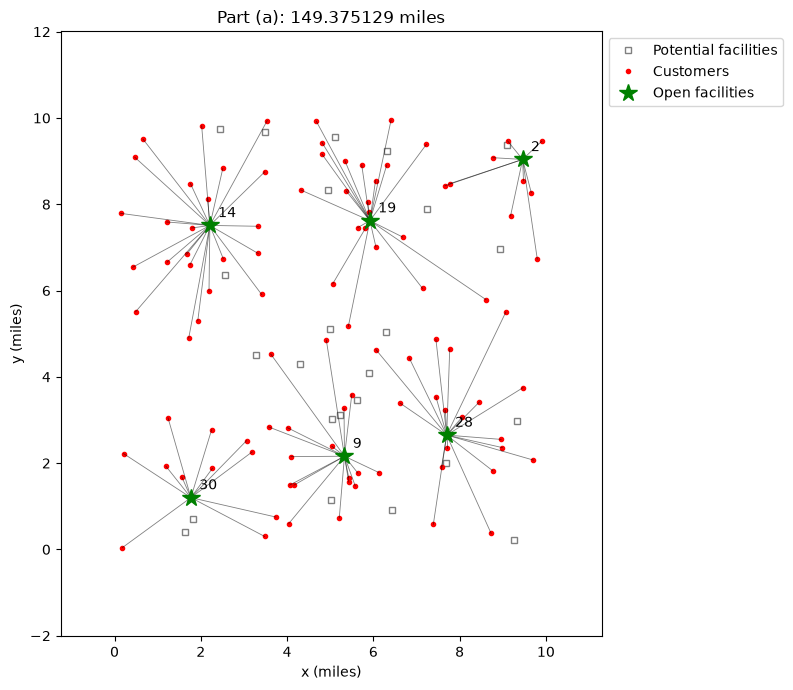

In [6]:
# Plot the facility locations, customer locations, and optimal connections.
matplotlib.pyplot.figure(figsize=(8, 7))
for fc in range(noFacs):
    matplotlib.pyplot.plot(facilities[fc][0], facilities[fc][1],
                           's', color='gray', markersize=5,
                           markerfacecolor='none',
                           label='Potential facilities' if fc == 0 else None)
for dp in range(noCusts):
    matplotlib.pyplot.plot(customers[dp][0], customers[dp][1],
                           'o', color='red', markersize=3,
                           label='Customers' if dp == 0 else None)
for dp in range(noCusts):
    dpx = customers[dp][0]
    dpy = customers[dp][1]
    fcx = facilities[assgns[dp]][0]
    fcy = facilities[assgns[dp]][1]
    matplotlib.pyplot.plot([dpx, fcx], [dpy, fcy],
                           color='black', linewidth=0.6, alpha=0.5)
for fc in openFacs:
    matplotlib.pyplot.plot(facilities[fc][0], facilities[fc][1],
                           '*', color='green', markersize=13,
                           label='Open facilities' if fc == openFacs[0] else None)
    matplotlib.pyplot.annotate(str(fc + 1), facilities[fc],
                               xytext=(6, 6), textcoords='offset points')
matplotlib.pyplot.xlabel('x (miles)')
matplotlib.pyplot.ylabel('y (miles)')
matplotlib.pyplot.title(f"Part ({part}): {model.ObjVal:.6f} miles")
matplotlib.pyplot.axis('equal')
matplotlib.pyplot.legend(loc='upper left', bbox_to_anchor=(1, 1))
matplotlib.pyplot.tight_layout()
matplotlib.pyplot.show()


In [7]:
model.dispose()

## (b) 
In addition to the model specification in Part a, we want to impose the additional
requirement that if we open a certain facility, then we must have another facility open within 3
miles of the opened facility. Give an integer programming formulation of the problem, solve the
problem by calling Gurobi within a programming language, state the optimal objective function
value and plot the optimal solution.

### Formulation
We use the objective and all constraints from part (a), and add the following constraint.

Let $N_j$ be the set of other facilities within 3 miles of facility $j$.

Thus,
$$y_j\le\sum_{k\in N_j}y_k\qquad\forall j \in \{1,...,30\}$$

In [8]:
part = 'b'
model = gp.Model('pmedian_' + part, env=env)
model.Params.MIPGap = 0
x = model.addVars(noCusts, noFacs, vtype=GRB.BINARY, name='x')
y = model.addVars(noFacs, vtype=GRB.BINARY, name='y')
model.setObjective(gp.quicksum(distances[i, j] * x[i, j]
                   for i in range(noCusts) for j in range(noFacs)),
                   GRB.MINIMIZE)
model.addConstrs((gp.quicksum(x[i, j] for j in range(noFacs)) == 1
                 for i in range(noCusts)), name='assign_once')
model.addConstrs((x[i, j] <= y[j]
                 for i in range(noCusts) for j in range(noFacs)),
                name='assign_to_open')
model.addConstr(gp.quicksum(y[j] for j in range(noFacs)) == p)

# A facility cannot count itself as its nearby open facility.
facility_hundredths = np.rint(np.array(facilities) * 100).astype(int)
neighbors = {}
for j in range(noFacs):
    neighbors[j] = [k for k in range(noFacs) if k != j and
                    np.sum((facility_hundredths[j] -
                            facility_hundredths[k]) ** 2) <= 300 ** 2]
model.addConstrs((y[j] <= gp.quicksum(y[k] for k in neighbors[j])
                 for j in range(noFacs)), name='nearby_open')
model.optimize()
assert model.Status == GRB.OPTIMAL

openFacs = [j for j in range(noFacs) if y[j].X > 0.5]
assgns = [next(j for j in range(noFacs) if x[i, j].X > 0.5)
          for i in range(noCusts)]

print(f'Optimal objective: {model.ObjVal:.9f} miles')
print(f'Best bound: {model.ObjBound:.9f}; MIP gap: {model.MIPGap:.1%}')
print('Open facility IDs:', [j + 1 for j in openFacs])
print('Facility ID | Coordinates | Customers assigned')
for j in openFacs:
    print(f'{j + 1:11d} | ({facilities[j][0]:.2f}, '
          f'{facilities[j][1]:.2f}) | {assgns.count(j)}')


Optimal objective: 163.516836807 miles
Best bound: 163.516836807; MIP gap: 0.0%
Open facility IDs: [10, 14, 17, 24, 25, 28]
Facility ID | Coordinates | Customers assigned
         10 | (4.96, 8.34) | 16
         14 | (2.21, 7.51) | 21
         17 | (5.04, 3.02) | 15
         24 | (5.02, 1.14) | 15
         25 | (7.25, 7.88) | 16
         28 | (7.70, 2.65) | 17


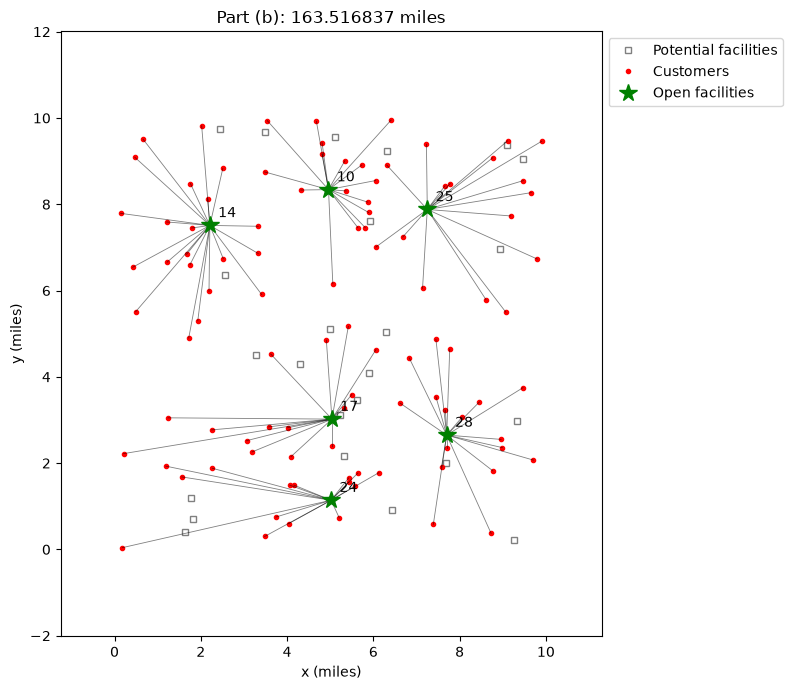

In [9]:
# Plot the facility locations, customer locations, and optimal connections.
matplotlib.pyplot.figure(figsize=(8, 7))
for fc in range(noFacs):
    matplotlib.pyplot.plot(facilities[fc][0], facilities[fc][1],
                           's', color='gray', markersize=5,
                           markerfacecolor='none',
                           label='Potential facilities' if fc == 0 else None)
for dp in range(noCusts):
    matplotlib.pyplot.plot(customers[dp][0], customers[dp][1],
                           'o', color='red', markersize=3,
                           label='Customers' if dp == 0 else None)
for dp in range(noCusts):
    dpx = customers[dp][0]
    dpy = customers[dp][1]
    fcx = facilities[assgns[dp]][0]
    fcy = facilities[assgns[dp]][1]
    matplotlib.pyplot.plot([dpx, fcx], [dpy, fcy],
                           color='black', linewidth=0.6, alpha=0.5)
for fc in openFacs:
    matplotlib.pyplot.plot(facilities[fc][0], facilities[fc][1],
                           '*', color='green', markersize=13,
                           label='Open facilities' if fc == openFacs[0] else None)
    matplotlib.pyplot.annotate(str(fc + 1), facilities[fc],
                               xytext=(6, 6), textcoords='offset points')
matplotlib.pyplot.xlabel('x (miles)')
matplotlib.pyplot.ylabel('y (miles)')
matplotlib.pyplot.title(f"Part ({part}): {model.ObjVal:.6f} miles")
matplotlib.pyplot.axis('equal')
matplotlib.pyplot.legend(loc='upper left', bbox_to_anchor=(1, 1))
matplotlib.pyplot.tight_layout()
matplotlib.pyplot.show()


In [10]:
model.dispose()

## (c) 
Go back to the model in Part a. In addition to the model specification in Part a, we
want to impose the additional requirement that if two customer locations are within 0.6 miles
of each other, then we cannot assign them to the same facility location. Give an integer
programming formulation of the problem, solve the problem by calling Gurobi within a
programming language, state the optimal objective function value and plot the optimal solution.

### Formulation

We use the model from part (a) without the extra constraints from part (b).

For every pair of customers $i$ and $h$ within 0.6 miles of each other, we add this constraint for every facility $j$:

$$x_{ij} + x_{hj} \le 1$$

This means the two customers cannot both be assigned to the same facility.

In [11]:
part = 'c'
model = gp.Model('pmedian_' + part, env=env)
model.Params.MIPGap = 0

x = model.addVars(noCusts, noFacs, vtype=GRB.BINARY, name='x')
y = model.addVars(noFacs, vtype=GRB.BINARY, name='y')

model.setObjective(gp.quicksum(distances[i, j] * x[i, j]
                   for i in range(noCusts) for j in range(noFacs)),
                   GRB.MINIMIZE)
model.addConstrs((gp.quicksum(x[i, j] for j in range(noFacs)) == 1
                 for i in range(noCusts)), name='assign_once')
model.addConstrs((x[i, j] <= y[j]
                 for i in range(noCusts) for j in range(noFacs)),
                name='assign_to_open')
model.addConstr(gp.quicksum(y[j] for j in range(noFacs)) == p)
# Each unordered customer pair appears exactly once.
customer_hundredths = np.rint(np.array(customers) * 100).astype(int)
close_pairs = [(i, h) for i in range(noCusts)
               for h in range(i + 1, noCusts)
               if np.sum((customer_hundredths[i] -
                          customer_hundredths[h]) ** 2) <= 60 ** 2]
model.addConstrs((x[i, j] + x[h, j] <= 1
                 for i, h in close_pairs for j in range(noFacs)),
                name='separate_customers')
model.optimize()
assert model.Status == GRB.OPTIMAL

openFacs = [j for j in range(noFacs) if y[j].X > 0.5]
assgns = [next(j for j in range(noFacs) if x[i, j].X > 0.5)
          for i in range(noCusts)]

print('Close customer pairs:', len(close_pairs))
print(f'Optimal objective: {model.ObjVal:.9f} miles')
print(f'Best bound: {model.ObjBound:.9f}; MIP gap: {model.MIPGap:.1%}')
print('Open facility IDs:', [j + 1 for j in openFacs])
print('Facility ID | Coordinates | Customers assigned')
for j in openFacs:
    print(f'{j + 1:11d} | ({facilities[j][0]:.2f}, '
          f'{facilities[j][1]:.2f}) | {assgns.count(j)}')


Close customer pairs: 47
Optimal objective: 209.710545510 miles
Best bound: 209.710545510; MIP gap: 0.0%
Open facility IDs: [10, 14, 17, 25, 28, 30]
Facility ID | Coordinates | Customers assigned
         10 | (4.96, 8.34) | 17
         14 | (2.21, 7.51) | 17
         17 | (5.04, 3.02) | 20
         25 | (7.25, 7.88) | 18
         28 | (7.70, 2.65) | 15
         30 | (1.77, 1.20) | 13


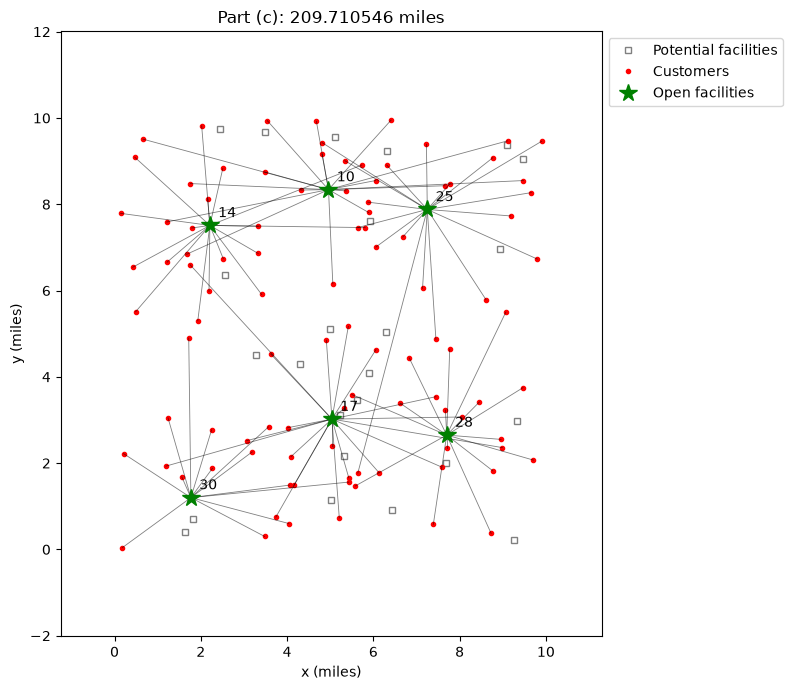

In [12]:
# Plot the facility locations, customer locations, and optimal connections.
matplotlib.pyplot.figure(figsize=(8, 7))
for fc in range(noFacs):
    matplotlib.pyplot.plot(facilities[fc][0], facilities[fc][1],
                           's', color='gray', markersize=5,
                           markerfacecolor='none',
                           label='Potential facilities' if fc == 0 else None)
for dp in range(noCusts):
    matplotlib.pyplot.plot(customers[dp][0], customers[dp][1],
                           'o', color='red', markersize=3,
                           label='Customers' if dp == 0 else None)
for dp in range(noCusts):
    dpx = customers[dp][0]
    dpy = customers[dp][1]
    fcx = facilities[assgns[dp]][0]
    fcy = facilities[assgns[dp]][1]
    matplotlib.pyplot.plot([dpx, fcx], [dpy, fcy],
                           color='black', linewidth=0.6, alpha=0.5)
for fc in openFacs:
    matplotlib.pyplot.plot(facilities[fc][0], facilities[fc][1],
                           '*', color='green', markersize=13,
                           label='Open facilities' if fc == openFacs[0] else None)
    matplotlib.pyplot.annotate(str(fc + 1), facilities[fc],
                               xytext=(6, 6), textcoords='offset points')
matplotlib.pyplot.xlabel('x (miles)')
matplotlib.pyplot.ylabel('y (miles)')
matplotlib.pyplot.title(f"Part ({part}): {model.ObjVal:.6f} miles")
matplotlib.pyplot.axis('equal')
matplotlib.pyplot.legend(loc='upper left', bbox_to_anchor=(1, 1))
matplotlib.pyplot.tight_layout()
matplotlib.pyplot.show()


In [13]:
model.dispose()

## (d) 
Both your team members should write and sign the following pledge: “Academic
integrity is expected of all students of Cornell University at all times, whether in the presence or
absence of members of the faculty. Understanding this, I declare that all of the team members
contributed equally to all stages of this homework assignment.”

<span style="color: pink;">Academic integrity is expected of all students of Cornell University at all times, whether in the presence or absence of members of the faculty. Understanding this, I declare that all of the team members contributed equally to all stages of this homework assignment.</span>

Ananya Shrivastava

<span style="color: blue;">Academic integrity is expected of all students of Cornell University at all times, whether in the presence or absence of members of the faculty. Understanding this, I declare that all of the team members contributed equally to all stages of this homework assignment.</span>

Hongzip Kim